# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('C:/Users/Dell/week07/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


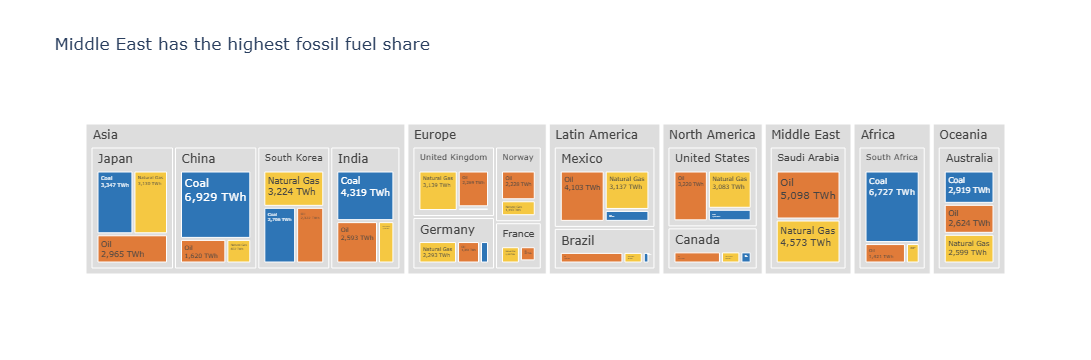

In [2]:
# Task 1
# YOUR CODE HERE

df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

source_colors = {
    'Coal': '#2E75B6',
    'Oil': '#E07B39',
    'Natural Gas': '#F5C842'
}

region_total = df.groupby('Region')['TWh'].sum()
region_fossil = df_fossil.groupby('Region')['TWh'].sum()

region_share = (region_fossil / region_total).sort_values(ascending=False)

top_region = region_share.idxmax()

fig = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=source_colors,
    title=f'{top_region} has the highest fossil fuel share'
)

fig.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh'
)

fig.data[0].marker.colors = [
    c if c in source_colors.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

fig.show()


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

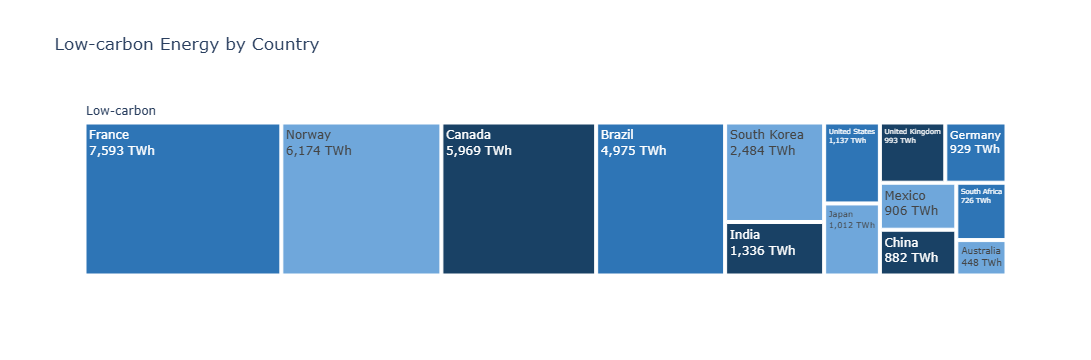

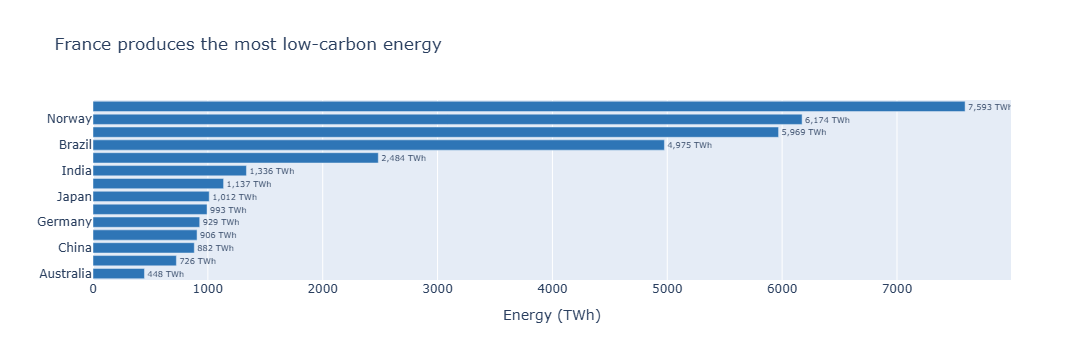

In [3]:
# Task 2 — charts
# YOUR CODE HERE

df_low = df.loc[df['Source_Type'] == 'Low-carbon'].copy()

low_country = df_low.groupby('Country')['TWh'].sum().reset_index()

low_country['All'] = 'Low-carbon'

top_country = low_country.loc[
    low_country['TWh'].idxmax(), 'Country'
]

fig = px.treemap(
    low_country,
    path=['All', 'Country'],
    values='TWh',
    color_discrete_sequence=['#2E75B6'],
    title='Low-carbon Energy by Country'
)

fig.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:,.0f} TWh'
)

fig.show()


low_country = low_country.sort_values(
    'TWh',
    ascending=True
)

fig = px.bar(
    low_country,
    x='TWh',
    y='Country',
    orientation='h',
    color_discrete_sequence=['#2E75B6'],
    title=f'{top_country} produces the most low-carbon energy'
)

fig.update_traces(
    texttemplate='%{x:,.0f} TWh',
    textposition='outside'
)

fig.update_layout(
    xaxis_title='Energy (TWh)',
    yaxis_title=''
)

fig.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*YOUR ANSWER HERE*

The horizontal bar chart shows the ranking more clearly because all bars share the same baseline. It is easier to compare values and identify the country with the highest low-carbon energy production

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

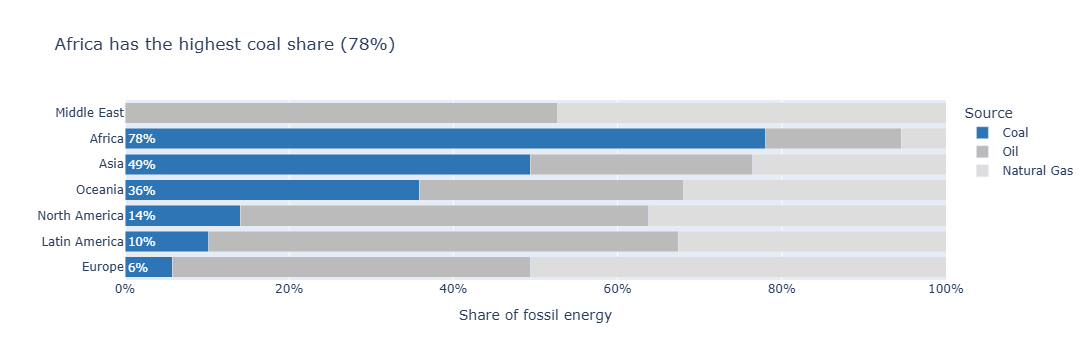

In [10]:
# Task 3
# YOUR CODE HERE

region_mix = df_fossil.groupby(
    ['Region', 'Source']
)['TWh'].sum().reset_index()

region_mix['Share'] = (
    region_mix['TWh'] /
    region_mix.groupby('Region')['TWh'].transform('sum')
)

coal_share = region_mix.loc[
    region_mix['Source'] == 'Coal'
].sort_values('Share', ascending=False)

region_order = coal_share['Region'].tolist()

top_region = coal_share.iloc[0]['Region']
top_share = coal_share.iloc[0]['Share']

region_mix['Label'] = np.where(
    region_mix['Source'] == 'Coal',
    region_mix['Share'].map('{:.0%}'.format),
    ''
)

colors = {
    'Coal': '#2E75B6',
    'Oil': '#BBBBBB',
    'Natural Gas': '#DDDDDD'
}

fig = px.bar(
    region_mix,
    x='Share',
    y='Region',
    color='Source',
    text='Label',
    orientation='h',
    color_discrete_map=colors,
    category_orders={
        'Region': region_order,
        'Source': ['Coal', 'Oil', 'Natural Gas']
    },
    title=f'{top_region} has the highest coal share ({top_share:.0%})'
)

fig.update_traces(
    textposition='inside',
    insidetextanchor='start'
)

fig.update_layout(
    barmode='stack',
    xaxis=dict(tickformat='.0%', range=[0, 1]),
    yaxis_title='',
    xaxis_title='Share of fossil energy'
)
fig.update_yaxes(
    categoryorder="array",
    categoryarray=region_order[::-1]
)
fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*YOUR ANSWER HERE*

The treemap shows the total fossil fuel consumption by region, country and source. The stacked bar chart shows the percentage share of coal, oil and natural gas in each region. The treemap helps compare total energy values, while the stacked bar helps identify which region depends most on coal.